In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.linear_model import RidgeClassifier, LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
import xgboost as xgb
from sklearn.inspection import permutation_importance

In [2]:
aqs_raw = pd.read_csv("../Data/LA_AQS_2023.csv")
waves = pd.read_csv('../Data/waves_2023.txt', sep=r'\s+')

## Part 1: EPA AQS linear classification

From HW07

In [3]:
aqs_raw["Date (Local)"] = pd.to_datetime(aqs_raw["Date (Local)"])

print(aqs_raw.shape)
aqs_raw.head()

(22160, 34)


,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
0,6,37,1103,68103,1,34.06659,-118.22688,WGS84,Ambient Min Temperature,24 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
1,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
2,6,37,1103,62201,1,34.06659,-118.22688,WGS84,Relative Humidity,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
3,6,37,1103,62101,1,34.06659,-118.22688,WGS84,Outdoor Temperature,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
4,6,37,1103,42603,1,34.06659,-118.22688,WGS84,Oxides of nitrogen (NOx),1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [4]:
o3 = aqs_raw[
    (aqs_raw["Parameter Name"] == "Ozone")
    & (aqs_raw["Duration Description"] == "1 HOUR")
][["Date (Local)", "Arithmetic Mean"]].copy()

o3 = o3.rename(columns={"Arithmetic Mean": "O3_ppm"})
o3["O3_ppb"] = o3["O3_ppm"] * 1000
o3.head()

,Date (Local),O3_ppm,O3_ppb
20,2023-01-01,0.031708,31.708
64,2023-01-02,0.015792,15.792
204,2023-01-03,0.025000,25.000
228,2023-01-04,0.020500,20.500
271,2023-01-05,0.027375,27.375


In [5]:
no2 = aqs_raw[
    (aqs_raw["Parameter Name"] == "Nitrogen dioxide (NO2)")
    & (aqs_raw["Pollutant Standard"] == "NO2 1-hour 2010")
][["Date (Local)", "Arithmetic Mean"]].copy()

no2 = (
    no2.groupby("Date (Local)", as_index=False)["Arithmetic Mean"]
    .mean()
    .rename(columns={"Arithmetic Mean": "NO2_ppb"})
)
no2.head()

,Date (Local),NO2_ppb
0,2023-01-01,4.683333
1,2023-01-02,15.068750
2,2023-01-03,11.662500
3,2023-01-04,14.363637
4,2023-01-05,11.027083


In [6]:
pm25 = aqs_raw[
    (aqs_raw["Parameter Name"] == "PM2.5 - Local Conditions")
    & (aqs_raw["Duration Description"] == "1 HOUR")
][["Date (Local)", "Arithmetic Mean"]].copy()

pm25 = (
    pm25.groupby("Date (Local)", as_index=False)["Arithmetic Mean"]
    .mean()
    .rename(columns={"Arithmetic Mean": "PM25_ugm3"})
)
pm25.head()

,Date (Local),PM25_ugm3
0,2023-01-01,5.087500
1,2023-01-02,9.187500
2,2023-01-03,4.312500
3,2023-01-04,4.266667
4,2023-01-05,6.704167


In [7]:
aqs = pd.merge(
    o3[["Date (Local)", "O3_ppb"]],
    no2,
    on="Date (Local)",
    how="inner",
)

aqs = pd.merge(aqs, pm25, on="Date (Local)", how="inner")
aqs = aqs.dropna().reset_index(drop=True)

print("Number of matched observations:", len(aqs))
aqs.head()

Number of matched observations: 271


,Date (Local),O3_ppb,NO2_ppb,PM25_ugm3
0,2023-01-01,31.708,4.683333,5.087500
1,2023-01-02,15.792,15.068750,9.187500
2,2023-01-03,25.000,11.662500,4.312500
3,2023-01-04,20.500,14.363637,4.266667
4,2023-01-05,27.375,11.027083,6.704167


In [8]:
aqs["month"] = aqs["Date (Local)"].dt.month


def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    if month in [6, 7, 8]:
        return "Summer"
    return np.nan


aqs["season"] = aqs["month"].apply(assign_season)
season_data = aqs.dropna(subset=["season"]).reset_index(drop=True)
season_data["season_code"] = season_data["season"].map(
    {"Winter": 0, "Summer": 1}
)

print(season_data["season"].value_counts())
print("Total summer and winter observations:", len(season_data))

season
Summer    92
Winter    59
Name: count, dtype: int64
Total summer and winter observations: 151


In [9]:
def stratified_split(
    data,
    label_column,
    train_fraction=0.60,
    validation_fraction=0.20,
    seed=31,
):
    random_generator = np.random.RandomState(seed)
    train_indices = []
    validation_indices = []
    test_indices = []

    for label in sorted(data[label_column].unique()):
        class_indices = data.index[data[label_column] == label].to_numpy().copy()
        random_generator.shuffle(class_indices)

        number_class = len(class_indices)
        number_train = int(np.floor(train_fraction * number_class))
        number_validation = int(np.floor(validation_fraction * number_class))

        train_indices.extend(class_indices[:number_train])
        validation_indices.extend(
            class_indices[number_train:number_train + number_validation]
        )
        test_indices.extend(class_indices[number_train + number_validation:])

    random_generator.shuffle(train_indices)
    random_generator.shuffle(validation_indices)
    random_generator.shuffle(test_indices)

    train = data.loc[train_indices].copy()
    validation = data.loc[validation_indices].copy()
    test = data.loc[test_indices].copy()

    return train, validation, test


train_data, validation_data, test_data = stratified_split(
    season_data,
    label_column="season_code",
    seed=31,
)

print("Training observations:", len(train_data))
print("Validation observations:", len(validation_data))
print("Testing observations:", len(test_data))

print("\nTraining classes:")
print(train_data["season"].value_counts())
print("\nValidation classes:")
print(validation_data["season"].value_counts())
print("\nTesting classes:")
print(test_data["season"].value_counts())

Training observations: 90
Validation observations: 29
Testing observations: 32

Training classes:
season
Summer    55
Winter    35
Name: count, dtype: int64

Validation classes:
season
Summer    18
Winter    11
Name: count, dtype: int64

Testing classes:
season
Summer    19
Winter    13
Name: count, dtype: int64


In [10]:
aqs_features = ['O3_ppb', 'NO2_ppb', 'PM25_ugm3']
development_data = pd.concat([train_data, validation_data], ignore_index=True)

X_development = development_data[aqs_features]
y_development = development_data['season_code']
X_aqs_test = test_data[aqs_features]
y_aqs_test = test_data['season_code']

development_mean = X_development.mean()
development_std = X_development.std(ddof=0)

X_development_scaled = (X_development - development_mean) / development_std
X_test_final_scaled = (X_aqs_test - development_mean) / development_std

ridge_final = RidgeClassifier(alpha=6.309573444801943)
ridge_final.fit(X_development_scaled, y_development)

logistic_final = LogisticRegression(C=10000, max_iter=10000)
logistic_final.fit(X_development_scaled, y_development)

aqs_models = {'Ridge classifier': ridge_final, 'Logistic regression': logistic_final}
aqs_scores = []

for name, model in aqs_models.items():
    predictions = model.predict(X_test_final_scaled)
    aqs_scores.append({
        'Model': name,
        'Test accuracy': accuracy_score(y_aqs_test, predictions),
        'Test error': 1 - accuracy_score(y_aqs_test, predictions)
    })

pd.DataFrame(aqs_scores)

,Model,Test accuracy,Test error
0,Ridge classifier,0.84375,0.15625
1,Logistic regression,0.87500,0.12500


### Permutation feature importance: classification

For each feature, PFI is the original test accuracy minus the accuracy after shuffling that feature. A larger positive value means a larger loss of accuracy. A value of 0.10 means a decrease of 10 percentage points.

The model stays fitted; only one test-data column is shuffled at a time. Each feature is shuffled 30 times. Error bars show one standard deviation across shuffles, not a confidence interval for the population.

In [11]:
aqs_pfi = {}
aqs_importance_rows = []

for name, model in aqs_models.items():
    result = permutation_importance(
        model, X_test_final_scaled, y_aqs_test,
        scoring='accuracy', n_repeats=30, random_state=31
    )
    aqs_pfi[name] = result

    for feature, mean, std in zip(
        aqs_features, result.importances_mean, result.importances_std
    ):
        aqs_importance_rows.append({
            'Model': name, 'Feature': feature, 'Mean PFI': mean, 'SD': std
        })

aqs_importance = pd.DataFrame(aqs_importance_rows)
aqs_importance.round(4)

,Model,Feature,Mean PFI,SD
0,Ridge classifier,O3_ppb,0.0156,0.0440
1,Ridge classifier,NO2_ppb,0.0896,0.0639
2,Ridge classifier,PM25_ugm3,0.0875,0.0445
3,Logistic regression,O3_ppb,-0.0083,0.0301
4,Logistic regression,NO2_ppb,0.2052,0.0789
5,Logistic regression,PM25_ugm3,0.2073,0.0742


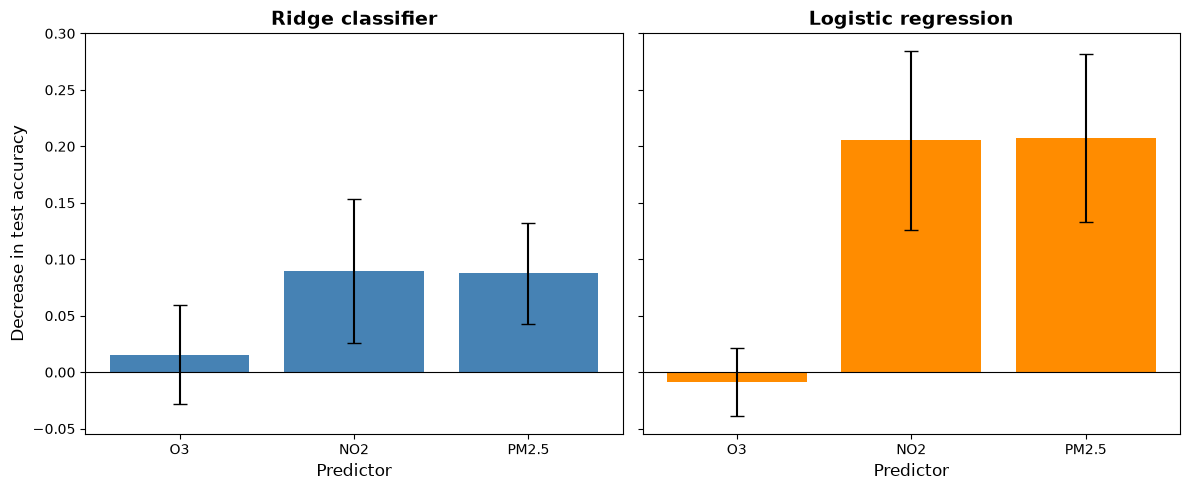

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
colors = ['steelblue', 'darkorange']

for ax, (name, result), color in zip(axes, aqs_pfi.items(), colors):
    ax.bar(['O3', 'NO2', 'PM2.5'], result.importances_mean,
           yerr=result.importances_std, capsize=5, color=color)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(name, fontsize=14, fontweight='bold')
    ax.set_xlabel('Predictor', fontsize=12)

axes[0].set_ylabel('Decrease in test accuracy', fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation

For **ridge classifier**, the importance ranking is **NO2_ppb > PM25_ugm3 > O3_ppb**. The largest mean decrease in accuracy is **0.090** for NO2_ppb.

For **logistic regression**, the importance ranking is **PM25_ugm3 > NO2_ppb > O3_ppb**. The largest mean decrease in accuracy is **0.207** for PM25_ugm3.

The two classifiers have different feature rankings, so they do not rely on the predictors in exactly the same way.

## Part 2: NOAA buoy wave-height prediction

From HW09

In [13]:
waves = waves.drop(['WDIR', 'WSPD', 'GST', 'PRES', 'ATMP', 'DEWP', 'VIS', 'TIDE'], axis=1)

waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

wavesML = waves.drop(['YY', 'MM', 'DD', 'hh', 'mm'], axis=1)
print('Cleaned observations:', len(wavesML))
wavesML.describe()

Cleaned observations: 17276


,WVHT,DPD,APD,MWD,WTMP
count,17276.000000,17276.000000,17276.000000,17276.000000,17276.000000
mean,1.032525,12.116640,6.765029,234.157965,17.195294
std,0.526637,3.664928,1.852623,46.260000,2.564729
min,0.330000,2.860000,3.420000,10.000000,11.800000
25%,0.730000,9.090000,5.500000,179.000000,14.600000
50%,0.880000,12.500000,6.360000,263.000000,17.500000
75%,1.140000,14.290000,7.550000,271.000000,19.400000
max,5.130000,25.000000,15.790000,306.000000,23.900000


In [14]:
wave_features = ['DPD', 'APD', 'MWD', 'WTMP']
df_X = wavesML[wave_features].to_numpy().copy()
df_y = wavesML['WVHT'].to_numpy().copy()

X_train, X_test, y_train, y_test = train_test_split(
    df_X, df_y, test_size=0.10, random_state=38
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.10, random_state=38
)

print('Training observations:', len(y_train))
print('Validation observations:', len(y_val))
print('Test observations:', len(y_test))

Training observations: 13993
Validation observations: 1555
Test observations: 1728


### Linear regression and decision tree

In [15]:
regL = LinearRegression()
regL.fit(X_train, y_train)

depths = [2, 4, 6, 8, 10, 15, 20, None]
tree_val_errors = []

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=38)
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    tree_val_errors.append(np.sqrt(mean_squared_error(y_val, predictions)))

best_depth = depths[int(np.argmin(tree_val_errors))]
regDT = DecisionTreeRegressor(max_depth=best_depth, random_state=38)
regDT.fit(X_train, y_train)

print('Selected maximum depth:', best_depth)
pd.DataFrame({
    'Maximum depth': [str(d) for d in depths],
    'Validation RMSE (m)': tree_val_errors
})

Selected maximum depth: 10


,Maximum depth,Validation RMSE (m)
0,2,0.430173
1,4,0.369086
2,6,0.348270
3,8,0.338722
4,10,0.316951
5,15,0.329727
6,20,0.368973
7,None,0.375770


In [16]:
wave_models = {'Linear regression': regL, 'Decision tree': regDT}
wave_scores = []

for name, model in wave_models.items():
    for split, X_data, y_data in [
        ('Train', X_train, y_train),
        ('Validation', X_val, y_val),
        ('Test', X_test, y_test)
    ]:
        predictions = model.predict(X_data)
        wave_scores.append({
            'Model': name, 'Dataset': split,
            'RMSE (m)': np.sqrt(mean_squared_error(y_data, predictions)),
            'R2': r2_score(y_data, predictions)
        })

pd.DataFrame(wave_scores).round(4)

,Model,Dataset,RMSE (m),R2
0,Linear regression,Train,0.4444,0.2910
1,Linear regression,Validation,0.4368,0.3305
2,Linear regression,Test,0.4304,0.2886
3,Decision tree,Train,0.2817,0.7150
4,Decision tree,Validation,0.3170,0.6475
5,Decision tree,Test,0.3189,0.6094


### Permutation feature importance

In [17]:
wave_pfi = {}
wave_importance_rows = []

for name, model in wave_models.items():
    result = permutation_importance(
        model, X_test, y_test,
        scoring='neg_root_mean_squared_error',
        n_repeats=30, random_state=38
    )
    wave_pfi[name] = result

    for feature, mean, std in zip(
        wave_features, result.importances_mean, result.importances_std
    ):
        wave_importance_rows.append({
            'Model': name, 'Feature': feature, 'Mean PFI (m)': mean, 'SD (m)': std
        })

pd.DataFrame(wave_importance_rows).round(4)

,Model,Feature,Mean PFI (m),SD (m)
0,Linear regression,DPD,0.0134,0.0019
1,Linear regression,APD,0.0922,0.0038
2,Linear regression,MWD,0.0158,0.0018
3,Linear regression,WTMP,0.0192,0.0018
4,Decision tree,DPD,0.1461,0.0072
5,Decision tree,APD,0.1922,0.0119
6,Decision tree,MWD,0.2037,0.0135
7,Decision tree,WTMP,0.1405,0.0106


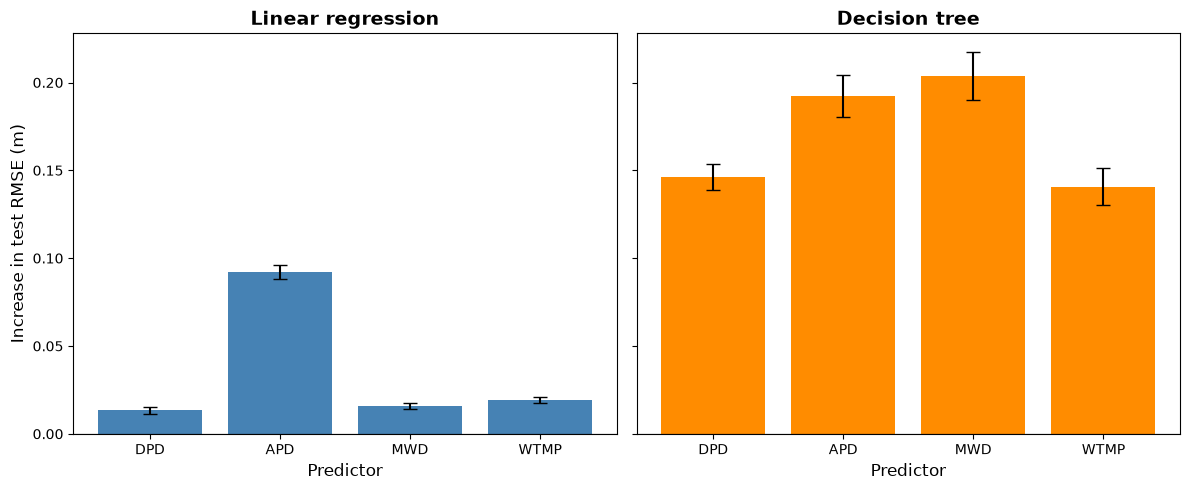

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (name, result), color in zip(axes, wave_pfi.items(), ['steelblue', 'darkorange']):
    ax.bar(wave_features, result.importances_mean,
           yerr=result.importances_std, capsize=5, color=color)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(name, fontsize=14, fontweight='bold')
    ax.set_xlabel('Predictor', fontsize=12)

axes[0].set_ylabel('Increase in test RMSE (m)', fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation of the executed models

For **linear regression**, the ranking is **APD > WTMP > MWD > DPD**. Shuffling APD increases test RMSE by **0.092 m** on average.

For **decision tree**, the ranking is **MWD > APD > DPD > WTMP**. Shuffling MWD increases test RMSE by **0.204 m** on average.

The rankings differ between the two models, showing that they rely on the predictors differently.

In [19]:
xgb_best = xgb.XGBRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=6,
    random_state=38, objective='reg:squarederror', n_jobs=2
)
xgb_best.fit(X_train, y_train)
wave_models['XGBoost'] = xgb_best

xgb_scores = []
for split, X_data, y_data in [
    ('Train', X_train, y_train),
    ('Validation', X_val, y_val),
    ('Test', X_test, y_test)
]:
    predictions = xgb_best.predict(X_data)
    xgb_scores.append({
        'Model': 'XGBoost', 'Dataset': split,
        'RMSE (m)': np.sqrt(mean_squared_error(y_data, predictions)),
        'R2': r2_score(y_data, predictions)
    })

pd.DataFrame(xgb_scores).round(4)

,Model,Dataset,RMSE (m),R2
0,XGBoost,Train,0.2203,0.8257
1,XGBoost,Validation,0.2895,0.7060
2,XGBoost,Test,0.2782,0.7026


In [20]:
xgb_pfi = permutation_importance(xgb_best, X_test, y_test, scoring='neg_root_mean_squared_error', n_repeats=30, random_state=38)
wave_pfi['XGBoost'] = xgb_pfi

pd.DataFrame({
    'Feature': wave_features,
    'Mean PFI (m)': xgb_pfi.importances_mean,
    'SD (m)': xgb_pfi.importances_std
}).round(4)

,Feature,Mean PFI (m),SD (m)
0,DPD,0.1355,0.0086
1,APD,0.1826,0.0086
2,MWD,0.1769,0.0104
3,WTMP,0.1644,0.0096


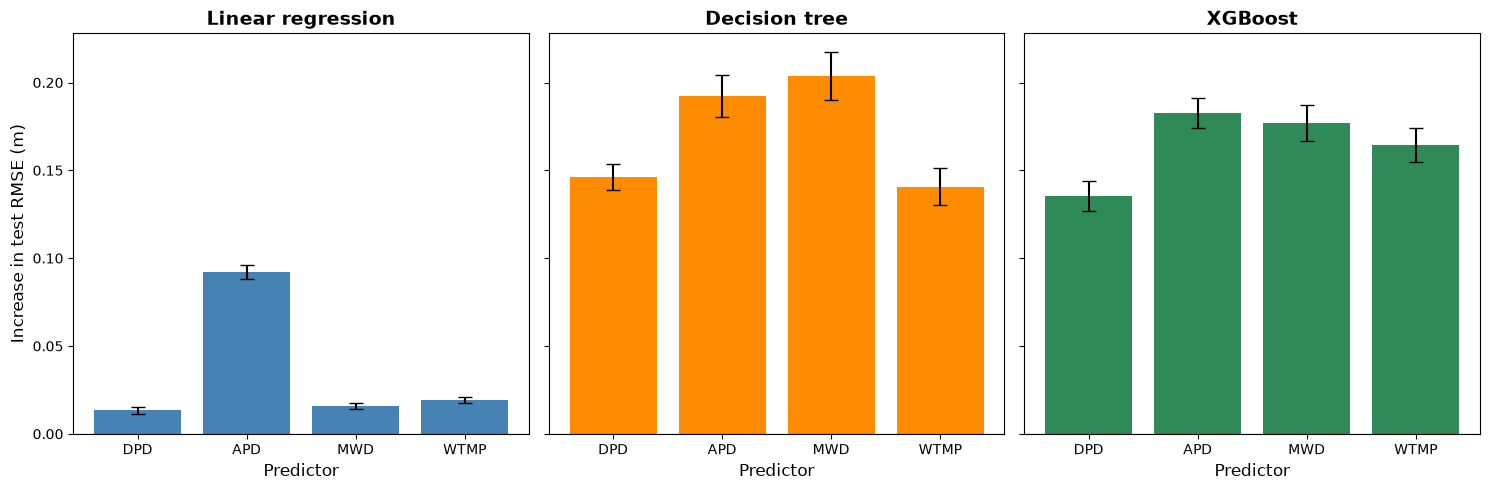

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, (name, result), color in zip(
    axes, wave_pfi.items(), ['steelblue', 'darkorange', 'seagreen']
):
    ax.bar(wave_features, result.importances_mean,
           yerr=result.importances_std, capsize=5, color=color)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(name, fontsize=14, fontweight='bold')
    ax.set_xlabel('Predictor', fontsize=12)

axes[0].set_ylabel('Increase in test RMSE (m)', fontsize=12)
plt.tight_layout()
plt.show()

### Question: Are the importances the same or different for different models?

In [22]:
wave_ranking = pd.DataFrame({
    name: np.array(wave_features)[np.argsort(-result.importances_mean)]
    for name, result in wave_pfi.items()
})
wave_ranking.index = [1, 2, 3, 4]
wave_ranking.index.name = 'Rank'
print(wave_ranking.to_string())


print('\nMost important feature for each model:')
for name, result in wave_pfi.items():
    index = int(np.argmax(result.importances_mean))
    print(f'{name}: {wave_features[index]}, PFI = {result.importances_mean[index]:.4f} m')

     Linear regression Decision tree XGBoost
Rank                                        
1                  APD           MWD     APD
2                 WTMP           APD     MWD
3                  MWD           DPD    WTMP
4                  DPD          WTMP     DPD

Most important feature for each model:
Linear regression: APD, PFI = 0.0922 m
Decision tree: MWD, PFI = 0.2037 m
XGBoost: APD, PFI = 0.1826 m


The feature importances differ across the models. **APD is most important for linear regression and XGBoost**, while **MWD is most important for the decision tree**. Shuffling these top features increases RMSE by approximately **0.0922 m, 0.1826 m, and 0.2037 m**, respectively. DPD ranks lowest for linear regression and XGBoost, while WTMP ranks lowest for the decision tree. These differences show that the models rely on the predictors differently.

## Part 3: Methods description

### Question 1: How do Flora et al. (2024) describe PFI?

Flora et al. describe **single-pass permutation importance**: shuffle one feature, measure the change in model quality, restore it, and repeat for each feature. Shuffling preserves that feature's distribution but disrupts its useful relationships. A larger performance loss indicates greater importance.

### Question 2: Describe an additional explainability method

**Accumulated local effects (ALE)** divides a feature's values into small intervals. Within each interval, it averages prediction changes between the interval boundaries, accumulates these changes, and centers the curve at zero. It shows how predictions vary with the feature. ALE is **model agnostic**, using model predictions. 

### Question 3: Potential functions for five methods

1. **Permutation importance:** `sklearn.inspection.permutation_importance()`
2. **Partial dependence:** `sklearn.inspection.PartialDependenceDisplay.from_estimator()`
3. **Regression coefficients:** `.coef_` from a fitted `LinearRegression` model.
4. **Impurity-based importance:** `.feature_importances_` from a fitted `RandomForestClassifier` model.
5. **Sequential feature selection:** `sklearn.feature_selection.SequentialFeatureSelector()`